In [134]:
from __future__ import annotations

import itertools
import warnings
from collections import defaultdict

import mne
import pathlib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scripts.dataset_manager import write_raw_dataset, read_raw_dataset

from math import ceil
from scipy import stats
from pyprep import NoisyChannels
from autoreject import AutoReject

mne.set_log_level("WARNING")

sns.set_theme(context='notebook', style='whitegrid')

In [109]:
raw_dataset = None
RAW_DATASET_NAME = pathlib.Path('data/raw_dataset.zip')
EPOCH_DATASET_NAME = pathlib.Path('data/epoch_dataset.zip')

EPOCH_TYPE = 'PinchLog'
EPOCH_TYPE_NOPINCH = 'NoPinchLog'
META_COL = 'PinchType'
CLASSES = ['PINCH', 'GAZE', 'PINCH_WIZARD_OF_OZ', 'PINCH_IGNORED']
PALETTE = dict(zip(CLASSES, sns.color_palette("Set2", len(CLASSES))))

In [110]:
raw = read_raw_dataset(RAW_DATASET_NAME)
epochs = read_raw_dataset(EPOCH_DATASET_NAME)

In [111]:
# region helper functions
def iter_sessions(d):
    """Yield (subject, session, value) over the nested dict, sorted."""
    for sub in sorted(d):
        for ses in sorted(d[sub]):
            yield sub, ses, d[sub][ses]


def get_pinchlog(epochs: mne.Epochs) -> mne.Epochs:
    """Return only the PinchLog epochs.

    Works whether 'PinchLog' is an event_id key, a prefix of hierarchical
    event ids ('PinchLog/pinch'), or a metadata column value.
    """
    if epochs.metadata is not None and "EpochType" in epochs.metadata:
        return epochs[f'EpochType == "{EPOCH_TYPE}"']
    keys = [k for k in epochs.event_id if EPOCH_TYPE in k]
    if not keys:
        raise KeyError(f"No {EPOCH_TYPE} events in {list(epochs.event_id)}")
    return epochs[keys]


def by_class(epochs: mne.Epochs, cls: str) -> mne.Epochs:
    """Select one PinchType level via the metadata query interface."""
    return epochs[f'{META_COL} == "{cls}"']


def stack_metadata(epochs_dict) -> pd.DataFrame:
    """Concatenate all PinchLog metadata into one long dataframe with keys."""
    rows = []
    for sub, ses, ep in iter_sessions(epochs_dict):
        ep = get_pinchlog(ep)
        md = ep.metadata.copy().reset_index(drop=True)
        md["subject"], md["session"] = sub, ses
        md["epoch_idx"] = np.arange(len(md))
        md["onset_s"] = ep.events[:, 0] / ep.info["sfreq"]
        rows.append(md)
    return pd.concat(rows, ignore_index=True)


def common_channels(epochs_dict) -> list[str]:
    """Intersection of channel names across every session (order preserved)."""
    sets = [set(ep.ch_names) for _, _, ep in iter_sessions(epochs_dict)]
    keep = set.intersection(*sets)
    first = next(iter_sessions(epochs_dict))[2]
    return [ch for ch in first.ch_names if ch in keep]

# endregion

# Sanity checks
Quick overview of the pinches that were measured in the sessions. The values are stable, and well distributed over the classes.

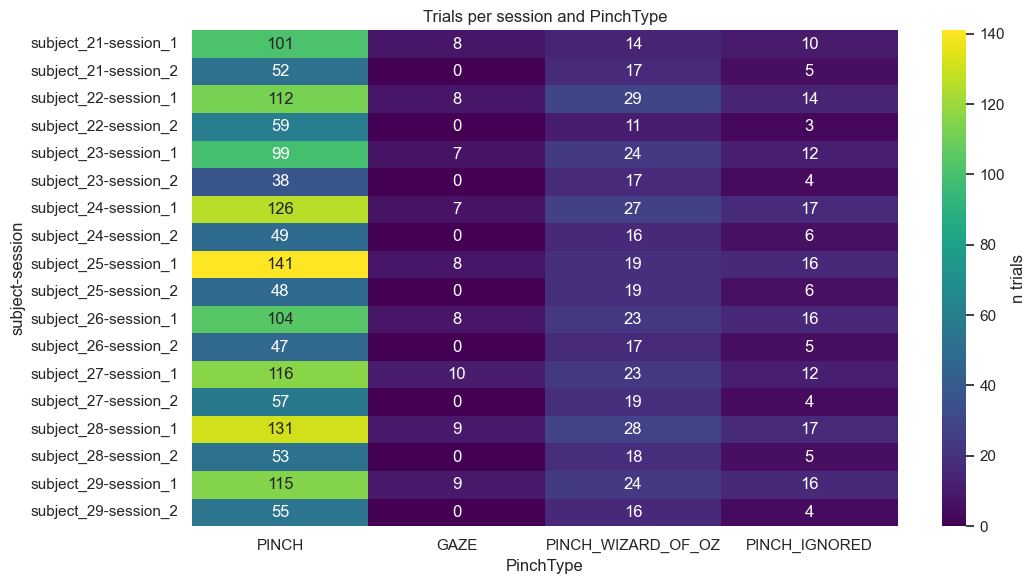

In [112]:
def plot_trial_inventory(epochs_dict, figsize=(11, 6)):
    md = stack_metadata(epochs_dict)
    tab = (md.groupby(["subject", "session", META_COL]).size()
             .unstack(fill_value=0).reindex(columns=CLASSES, fill_value=0))

    fig, axes = plt.subplots(1, 1, figsize=figsize)
    sns.heatmap(tab, annot=True, fmt="d", cmap="viridis", ax=axes,
                cbar_kws={"label": "n trials"})
    axes.set_title("Trials per session and PinchType")

    fig.tight_layout()
    return fig, tab
_ = plot_trial_inventory(epochs)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


def plot_eeg_stats(stats: dict, data: dict):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # --- 1. Mean session duration ---
    ax = axes[0, 0]
    dur = stats['mean_session_duration']
    ax.bar(dur['session'], dur['mean_duration_s'], color='steelblue')
    ax.set_title('Mean Session Duration')
    ax.set_ylabel('Duration (s)')
    for i, v in enumerate(dur['mean_duration_s']):
        ax.text(i, v, f'{v:.0f}s', ha='center', va='bottom')

    # --- 2. Mean marker counts per EventType ---
    ax = axes[0, 1]
    ev = stats['mean_event_type_counts'].sort_values('mean_count', ascending=True)
    ax.barh(ev['EventType'], ev['mean_count'], color='darkorange')
    ax.set_title('Mean Marker Count per EventType')
    ax.set_xlabel('Mean count per session')

    # --- 3. Mean PinchType counts ---
    ax = axes[1, 0]
    pt = stats['mean_pinch_type_counts'].sort_values('mean_count', ascending=True)
    if not pt.empty:
        ax.barh(pt['PinchType'].astype(str), pt['mean_count'], color='seagreen')
        ax.set_title('Mean Count per PinchType')
        ax.set_xlabel('Mean count per session')
    else:
        ax.text(0.5, 0.5, 'No PinchType data', ha='center', va='center')
        ax.set_title('Mean Count per PinchType')

    # --- 4. Bad electrodes heatmap (subject x session) ---
    ax = axes[1, 1]
    bad_df = stats['bad_electrodes_per_session']
    pivot = bad_df.pivot(index='subject', columns='session', values='n_bad')
    im = ax.imshow(pivot.values, cmap='Reds', aspect='auto')
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=45, ha='right')
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_title('# Bad Electrodes (subject x session)')
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            val = pivot.values[i, j]
            if not np.isnan(val):
                ax.text(j, i, int(val), ha='center', va='center',
                        color='white' if val > pivot.values.max() / 2 else 'black')
    fig.colorbar(im, ax=ax, label='n_bad')

    plt.tight_layout()
    plt.savefig('eeg_stats_overview.png', dpi=150)
    plt.show()


def plot_bad_electrode_frequency(data: dict):
    """Which specific electrodes are most often marked bad, across all sessions."""
    from collections import Counter

    counter = Counter()
    for subject, sessions in data.items():
        for session, d in sessions.items():
            counter.update(d['eeg'].info['bads'])

    if not counter:
        print("No bad electrodes found.")
        return

    chans, counts = zip(*counter.most_common())
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(chans, counts, color='crimson')
    ax.set_title('Frequency of Electrodes Marked Bad (across all subjects/sessions)')
    ax.set_ylabel('# sessions marked bad')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig('bad_electrode_frequency.png', dpi=150)
    plt.show()

import mne
import numpy as np
import pandas as pd


def eeg_dataset_stats(data: dict) -> dict:
    """
    data: {subject: {session: {'eeg': mne.Raw, 'markers': pd.DataFrame, ...}}}
    Returns a dict of DataFrames, one per requested stat.
    """
    duration_rows = []
    event_type_rows = []
    pinch_type_rows = []
    bad_electrode_rows = []

    for subject, sessions in data.items():
        for session, d in sessions.items():
            eeg = d['eeg']
            markers = d['markers']

            # --- session duration ---
            duration_s = eeg.times[-1] - eeg.times[0]
            duration_rows.append({
                'subject': subject, 'session': session, 'duration_s': duration_s
            })

            # --- marker counts per EventType ---
            event_counts = markers['EventType'].value_counts()
            for event_type, count in event_counts.items():
                event_type_rows.append({
                    'subject': subject, 'session': session,
                    'EventType': event_type, 'count': count
                })

            # --- PinchType counts, restricted to EventType == 'PinchType' ---
            pinch_events = markers[markers['EventType'] == 'PinchType']
            pinch_counts = pinch_events['PinchType'].value_counts()
            for pinch_type, count in pinch_counts.items():
                pinch_type_rows.append({
                    'subject': subject, 'session': session,
                    'PinchType': pinch_type, 'count': count
                })

            # --- bad electrodes ---
            bads = eeg.info['bads']
            bad_electrode_rows.append({
                'subject': subject, 'session': session,
                'n_bad': len(bads), 'bad_channels': bads
            })

    duration_df = pd.DataFrame(duration_rows)
    event_type_df = pd.DataFrame(event_type_rows)
    pinch_type_df = pd.DataFrame(pinch_type_rows)
    bad_electrode_df = pd.DataFrame(bad_electrode_rows)

    # --- aggregations ---

    # mean session duration, per session label (session_1, session_2, ...)
    mean_duration = (
        duration_df.groupby('session')['duration_s']
        .mean()
        .rename('mean_duration_s')
        .reset_index()
    )

    # mean number of markers per EventType (averaged across subject/session
    # occurrences; sessions where a given EventType never occurs count as 0)
    all_sessions = duration_df[['subject', 'session']].drop_duplicates()
    event_full = (
        all_sessions.merge(event_type_df[['EventType']].drop_duplicates(), how='cross')
        .merge(event_type_df, on=['subject', 'session', 'EventType'], how='left')
        .fillna({'count': 0})
    )
    mean_event_counts = (
        event_full.groupby('EventType')['count']
        .mean()
        .rename('mean_count')
        .reset_index()
    )

    # mean number of entries per PinchType value (same zero-fill logic)
    if not pinch_type_df.empty:
        pinch_full = (
            all_sessions.merge(pinch_type_df[['PinchType']].drop_duplicates(), how='cross')
            .merge(pinch_type_df, on=['subject', 'session', 'PinchType'], how='left')
            .fillna({'count': 0})
        )
        mean_pinch_counts = (
            pinch_full.groupby('PinchType')['count']
            .mean()
            .rename('mean_count')
            .reset_index()
        )
    else:
        mean_pinch_counts = pd.DataFrame(columns=['PinchType', 'mean_count'])

    return {
        'mean_session_duration': mean_duration,
        'mean_event_type_counts': mean_event_counts,
        'mean_pinch_type_counts': mean_pinch_counts,
        'bad_electrodes_per_session': bad_electrode_df,
    }

stats = eeg_dataset_stats(raw_dataset)
plot_eeg_stats(stats, raw_dataset)
plot_bad_electrode_frequency(raw_dataset)

Short sanity check to make sure that events are distributed over the full session. This makes sure that classifications will not be trivial when classifiers learn electrode drift, fatigue due to session duration.

The diagram shows a pretty good distribution over the entire experiment with an exception to the end of the experiment, as there is a control experiment there.

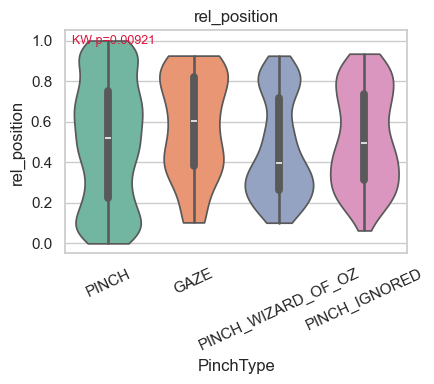

In [113]:
def plot_design_confounds(epochs_dict, extra_cols=("ReactionTime",)):
    md = stack_metadata(epochs_dict)
    md["rel_position"] = md.groupby(["subject", "session"])["epoch_idx"] \
                           .transform(lambda s: s / max(s.max(), 1))

    col = "rel_position"
    fig, ax = plt.subplots(1, 1, figsize=(4.5, 4))
    sns.violinplot(data=md, x=META_COL, y=col, order=CLASSES,
                   hue=META_COL, hue_order=CLASSES, palette=PALETTE,
                   legend=False, cut=0, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=25)

    groups = [g[col].dropna().values for _, g in md.groupby(META_COL)]
    if all(len(g) > 1 for g in groups):
        H, p = stats.kruskal(*groups)
        ax.text(.02, .98, f"KW p={p:.3g}", transform=ax.transAxes,
                va="top", fontsize=9,
                color="crimson" if p < .01 else "gray")
    fig.tight_layout()
    return fig, md

_ = plot_design_confounds(epochs)

# Signal and channel quality

At first glance, not all measurements were of good quality.

Observed issues:

- Missing alpha-bump at 8-12Hz for some measurements
- Overall high PSD for some measurements, indicating high noise/drift.

C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\mne\time_frequency\psd.py:292: UserWarning: nperseg = 1200 is greater than input length  = 87, using nperseg = 87
  return _func(*args, **kwargs)
C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\mne\time_frequency\psd.py:292: UserWarning: nperseg = 1200 is greater than input length  = 154, using nperseg = 154
  return _func(*args, **kwargs)
C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\mne\time_frequency\psd.py:292: UserWarning: nperseg = 1200 is greater than input length  = 95, using nperseg = 95
  return _func(*args, **kwargs)
C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\mne\time_frequency\psd.py:292: UserWarning: nperseg = 1200 is greater than input length  = 114, using nperseg = 114
  return _func(*args, **kwargs)
C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\mne\time_frequency\psd.py:292: UserWarning: nperseg = 1200 is greater than input length  = 2

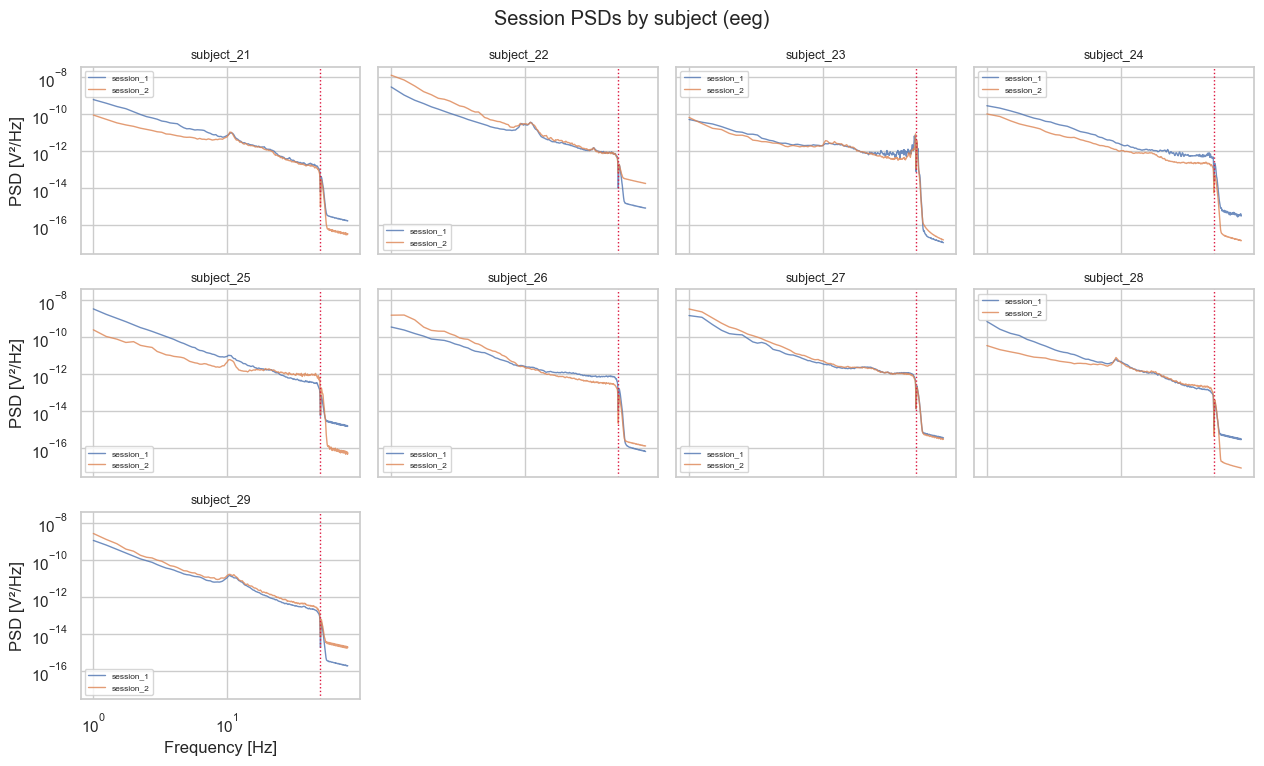

In [137]:
def plot_session_psds_by_subject(raws_dict, fmax=80, picks="eeg", figsize=None,
                                  eeg_field_name="eeg_raw", n_cols=4):
    # First pass: compute PSDs, capping n_fft to each recording's actual length
    # so we never ask Welch's method for a longer segment than exists.
    records = []
    for sub, ses, raw_dict in iter_sessions(raws_dict):
        raw_eeg = raw_dict[eeg_field_name]
        psd = raw_eeg.compute_psd(fmin=1, fmax=fmax, picks=picks, n_fft=int(4 * raw_eeg.info["sfreq"]))
        f = psd.freqs
        m = psd.get_data().mean(axis=0)
        records.append((sub, ses, f, m))

    subjects = sorted(set(r[0] for r in records))
    n_cols = min(n_cols, len(subjects))
    n_rows = ceil(len(subjects) / n_cols)
    if figsize is None:
        figsize = (3.2 * n_cols, 2.6 * n_rows)

    # sharex/sharey guarantees every panel spans the exact same axis range
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize,
                              sharex=True, sharey=True, squeeze=False)
    axes_flat = axes.ravel()

    for ax, sub in zip(axes_flat, subjects):
        for s, ses, f, m in records:
            if s != sub:
                continue
            ax.loglog(f, m, lw=1, alpha=.8, label=ses)
        for hz in (50, 100):
            if hz < fmax:
                ax.axvline(hz, color="crimson", ls=":", lw=1)
        ax.set_title(sub, fontsize=9)
        ax.legend(fontsize=6)

    for ax in axes_flat[len(subjects):]:  # hide unused grid cells
        ax.axis("off")
    for ax in axes[-1, :]:
        ax.set_xlabel("Frequency [Hz]")
    for ax in axes[:, 0]:
        ax.set_ylabel("PSD [V²/Hz]")

    fig.suptitle(f"Session PSDs by subject ({eeg_field_name})")
    fig.tight_layout()
    return fig

_ = plot_session_psds_by_subject(raw, eeg_field_name="eeg")

Analyse channel quality as pyprep.NoisyChannels. This technique is based on the PREP pipeline (Bigdely-Shamlo et al. 2015). The metrics are:

- deviation_z
- hf_noise: high frequency noise
- corr_median: the correlation with other channels
- corr_bad_frac: fraction of 1-s windows where the maximum correlation fell below .4
- dropout_frac: fraction of flat signal windows
- psd_z: comparison of PSD to other channels

As expected, Fz is bad. Unexpectedly, other channels are marked as bad.

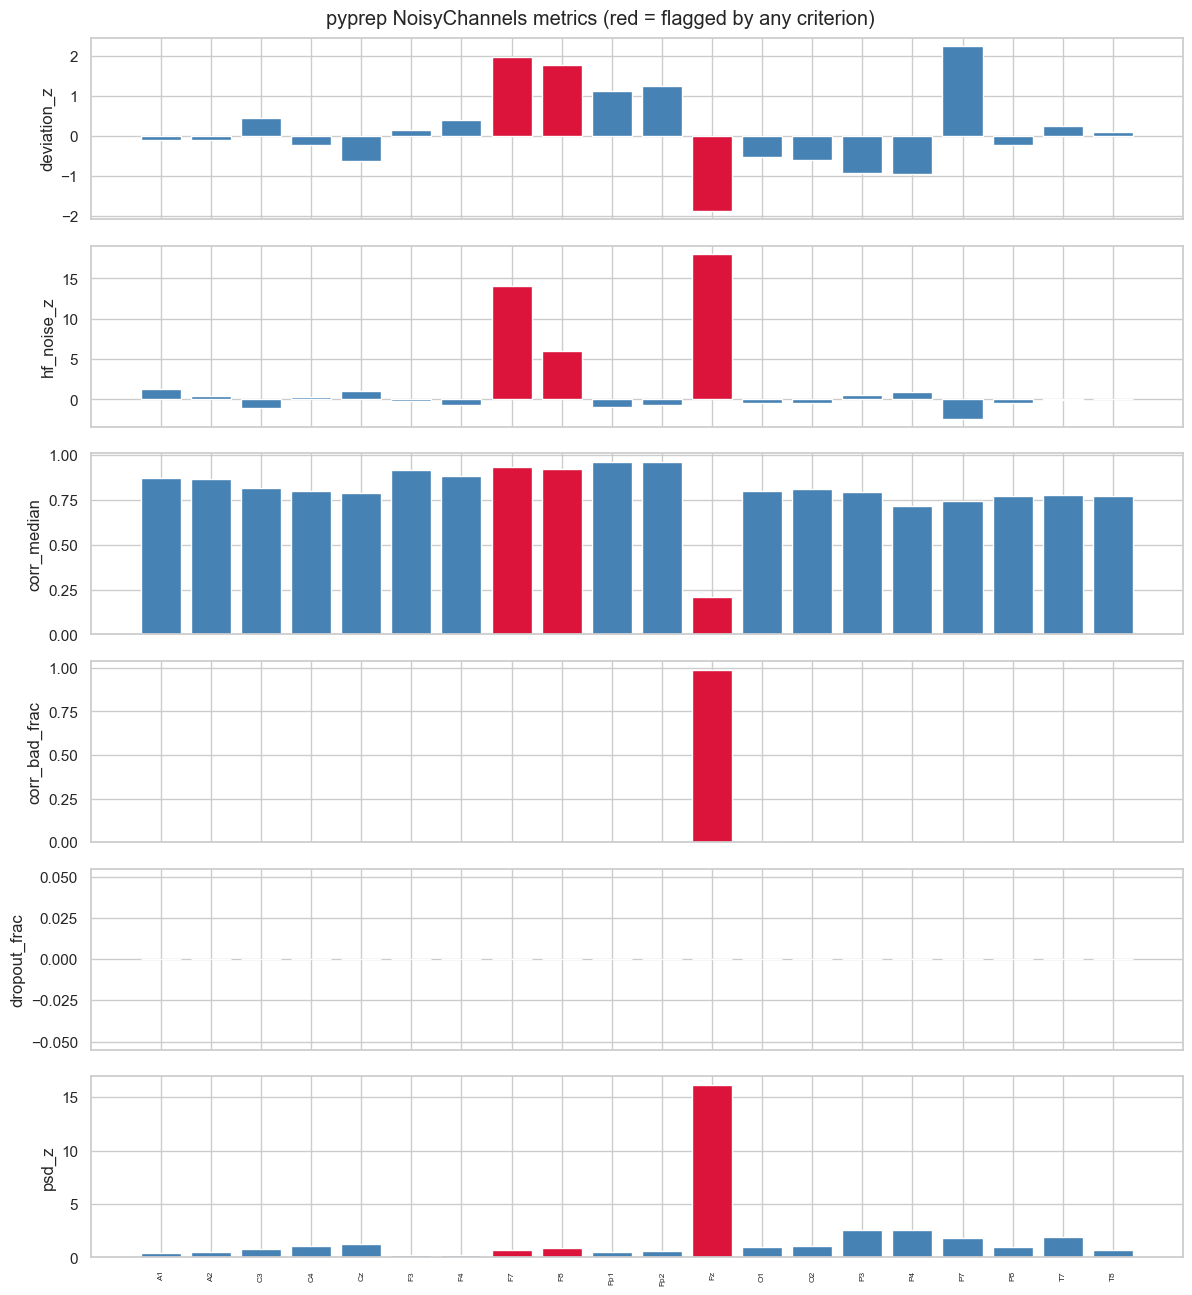

In [115]:
def channel_quality_table_pyprep(raw, ransac=False, **nc_kwargs):
    raw_eeg = raw['eeg_raw'].copy().pick("eeg")
    # NoisyChannels detrends (<1 Hz) internally by default (do_detrend=True)
    nc = NoisyChannels(raw_eeg, random_state=97, ransac=ransac, **nc_kwargs)
    nc.find_all_bads(ransac=ransac)

    ch = list(nc.ch_names_original)
    info = nc._extra_info

    df = pd.DataFrame({"ch": ch})
    df["deviation_z"]   = info["bad_by_deviation"].get("robust_channel_deviations", np.nan)
    df["hf_noise_z"]    = info["bad_by_hf_noise"].get("hf_noise_zscores", np.nan)
    df["corr_median"]   = info["bad_by_correlation"].get("median_max_correlations", np.nan)
    df["corr_bad_frac"] = info["bad_by_correlation"].get("bad_window_fractions", np.nan)
    df["dropout_frac"]  = info["bad_by_dropout"].get("bad_window_fractions", np.nan)
    df["psd_z"]         = info["bad_by_psd"].get("psd_zscore", np.nan)
    if ransac:
        df["ransac_bad_frac"] = info["bad_by_ransac"].get("bad_window_fractions", np.nan)

    flag_map = {
        "flag_nan":         nc.bad_by_nan,
        "flag_flat":        nc.bad_by_flat,
        "flag_deviation":   nc.bad_by_deviation,
        "flag_hf_noise":    nc.bad_by_hf_noise,
        "flag_correlation": nc.bad_by_correlation,
        "flag_dropout":     nc.bad_by_dropout,
        "flag_snr":         nc.bad_by_SNR,
        "flag_psd":         nc.bad_by_psd,
    }
    if ransac:
        flag_map["flag_ransac"] = nc.bad_by_ransac

    for col, bad_list in flag_map.items():
        df[col] = df["ch"].isin(bad_list)

    df["flag_any"] = df[[c for c in df.columns if c.startswith("flag_")]].any(axis=1)
    return df.sort_values("flag_any", ascending=False)


def plot_channel_quality_pyprep(raw, ransac=False, **nc_kwargs):
    df = channel_quality_table_pyprep(raw, ransac=ransac, **nc_kwargs).sort_values("ch")
    metrics = ["deviation_z", "hf_noise_z", "corr_median", "corr_bad_frac", "dropout_frac", "psd_z"]
    if ransac:
        metrics.append("ransac_bad_frac")

    fig, axes = plt.subplots(len(metrics), 1, figsize=(12, 2.2 * len(metrics)), sharex=True)
    for ax, m in zip(axes, metrics):
        colors = ["crimson" if f else "steelblue" for f in df["flag_any"]]
        ax.bar(df["ch"], df[m], color=colors)
        ax.set_ylabel(m)
    axes[-1].tick_params(axis="x", rotation=90, labelsize=6)
    fig.suptitle("pyprep NoisyChannels metrics (red = flagged by any criterion)")
    fig.tight_layout()
    return fig, df

_ = plot_channel_quality_pyprep(raw['subject_28']['session_1'])

Looking over the whole session, it becomes clear that mostly the tutorial part is noisy. This is the part where the participant is still speaking, moving their head, possibly the headset. This part has to be removed before any processing as it would get everything wrong.

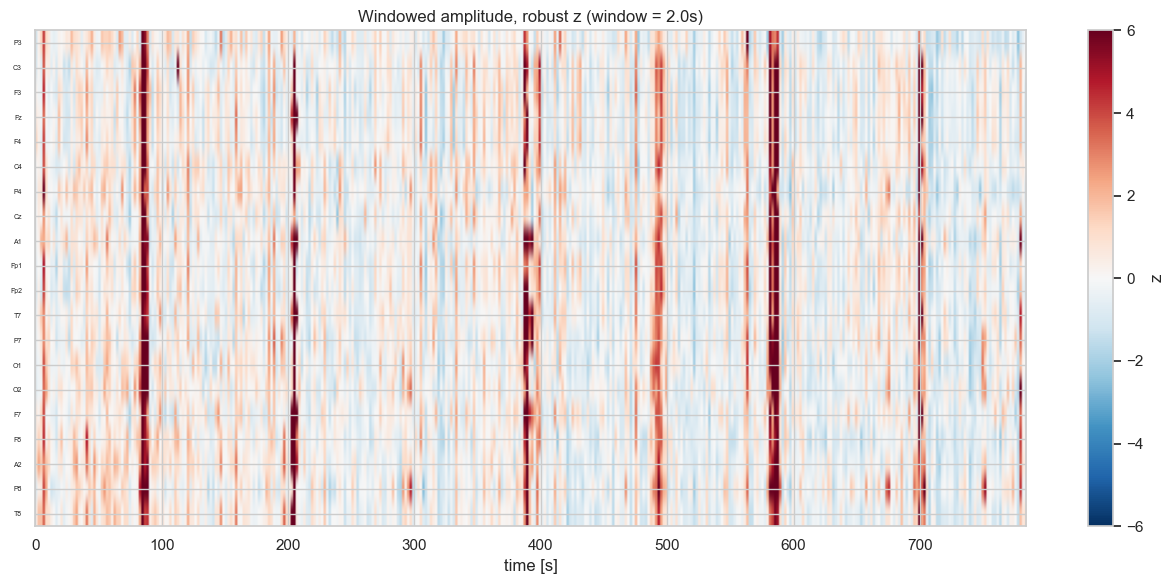

In [116]:
def plot_quality_carpet(raw, win_s=2.0, clip=6):
    raw = raw.copy().pick("eeg")
    X = raw.get_data()
    sf = raw.info["sfreq"]
    n = int(win_s * sf)
    nwin = X.shape[1] // n
    W = X[:, : nwin * n].reshape(len(X), nwin, n)
    amp = W.std(axis=2)

    med = np.median(amp, axis=1, keepdims=True)
    mad = stats.median_abs_deviation(amp, axis=1, scale="normal")[:, None]
    Z = np.clip((amp - med) / np.where(mad == 0, np.nan, mad), -clip, clip)

    fig, ax = plt.subplots(figsize=(13, 6))
    im = ax.imshow(Z, aspect="auto", cmap="RdBu_r", vmin=-clip, vmax=clip,
                   extent=[0, nwin * win_s, len(X), 0])
    ax.set_yticks(np.arange(len(X)) + .5)
    ax.set_yticklabels(raw.ch_names, fontsize=5)
    ax.set_xlabel("time [s]")
    ax.set_title(f"Windowed amplitude, robust z (window = {win_s}s)")
    fig.colorbar(im, ax=ax, label="z")
    fig.tight_layout()
    return fig, Z
_ = plot_quality_carpet(raw['subject_28']['session_2']['eeg'])

ICA analysis on the filtered and interpolated signal. eye blink as well as heart beat was identified. The fully preprocessed data wont contain these.

C:\Users\nicol\AppData\Local\Temp\ipykernel_31984\3946580803.py:10: RuntimeWarning: The provided Raw instance does not seem to be referenced to a common average reference (CAR). ICLabel was designed to classify features extracted from an EEG dataset referenced to a CAR (see the 'set_eeg_reference()' method for Raw and Epochs instances).
  labels = label_components(raw_ica, ica, method="iclabel")
C:\Users\nicol\AppData\Local\Temp\ipykernel_31984\3946580803.py:10: RuntimeWarning: The provided ICA instance was fitted with a 'picard' algorithm. ICLabel was designed with extended infomax ICA decompositions. To use the extended infomax algorithm, use the 'mne.preprocessing.ICA' instance with the arguments 'ICA(method='infomax', fit_params=dict(extended=True))' (scikit-learn) or 'ICA(method='picard', fit_params=dict(ortho=False, extended=True))' (python-picard).
  labels = label_components(raw_ica, ica, method="iclabel")


        label      prob
0       brain  0.416039
1       other  0.500106
2   eye blink  0.978725
3       brain  0.774912
4       brain  0.733157
5       brain  0.826982
6       other  0.699039
7       other  0.508423
8       other  0.442421
9       other  0.496014
10      brain  0.795524


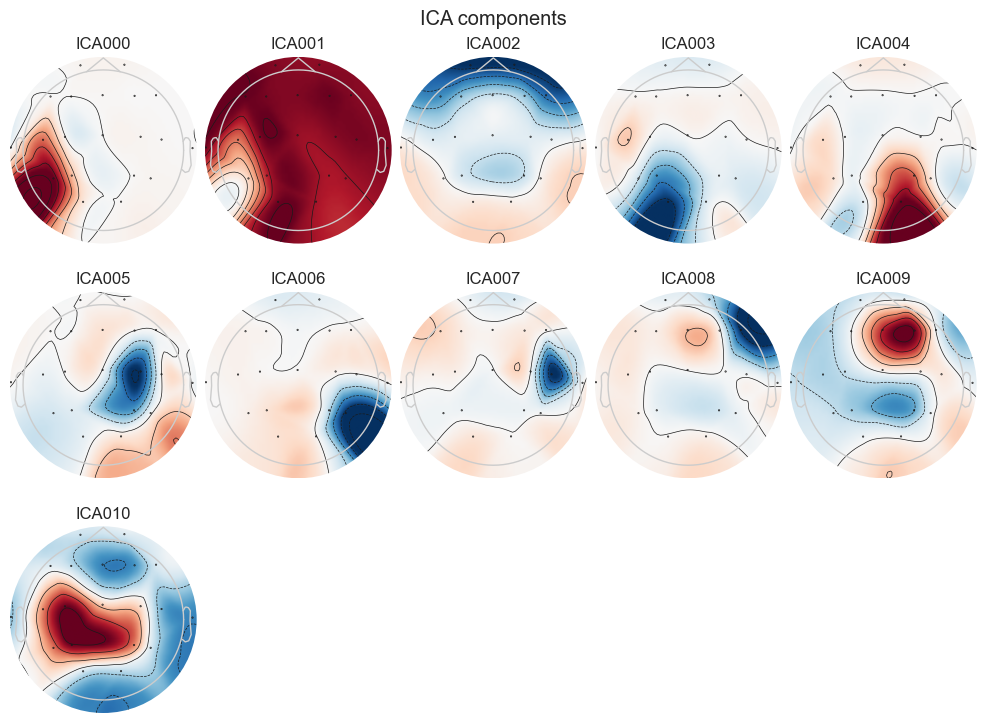

In [125]:
def run_ica_review(raw, n_components=.99, eog_ch=None, method="picard"):
    raw_ica = raw.copy().filter(1., 100., picks="eeg")
    ica = mne.preprocessing.ICA(n_components=n_components, method=method,
                                max_iter="auto", random_state=42)
    ica.fit(raw_ica, picks="eeg")

    labels = None
    try:
        from mne_icalabel import label_components
        labels = label_components(raw_ica, ica, method="iclabel")
        print(pd.DataFrame({"label": labels["labels"],
                            "prob": labels["y_pred_proba"]}))
    except ImportError:
        warnings.warn("mne_icalabel not installed; falling back to EOG correlation")

    ica.plot_components(inst=raw_ica)
    if eog_ch is not None:
        idx, scores = ica.find_bads_eog(raw_ica, ch_name=eog_ch)
        ica.plot_scores(scores, exclude=idx)
        print("EOG-correlated components:", idx)
    return ica, labels

_ = run_ica_review(raw['subject_28']['session_1']['eeg_noise_removed'])

# Epoch-Level quality

Epoch quality is assessed by a per-epoch peak-to-peak amplitude. Amplitude distribution should be the same across classes, and also participants.

But we discover that some participants have many epochs with high ptp amplitude values. These are probably bad.

C:\Users\nicol\AppData\Local\Temp\ipykernel_31984\720356921.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=META_COL, y="ptp_uv", order=CLASSES,


Kruskal-Wallis amplitude ~ PinchType: H=1.3, p=0.727


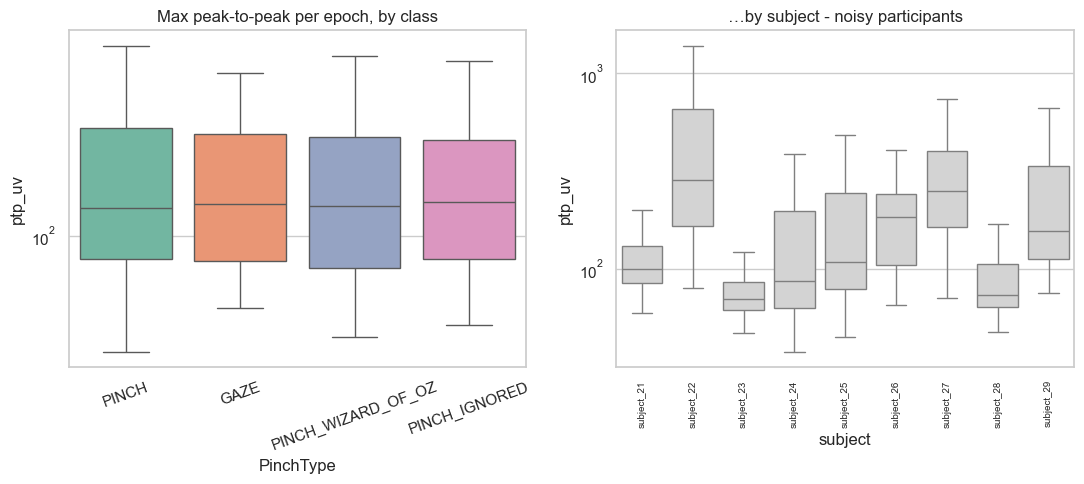

In [130]:
def plot_ptp_by_class(epochs_dict, picks="eeg", figsize=(11, 5)):
    rows = []
    for sub, ses, ep in iter_sessions(epochs_dict):
        ep = get_pinchlog(ep).copy().pick(picks)
        X = ep.get_data()
        ptp = (X.max(axis=2) - X.min(axis=2)).max(axis=1) * 1e6  # µV
        rows.append(pd.DataFrame(dict(subject=sub, session=ses,
                                      ptp_uv=ptp,
                                      **{META_COL: ep.metadata[META_COL].values})))
    df = pd.concat(rows, ignore_index=True)

    fig, axes = plt.subplots(1, 2, figsize=figsize)
    sns.boxplot(data=df, x=META_COL, y="ptp_uv", order=CLASSES,
                palette=PALETTE, showfliers=False, ax=axes[0])
    axes[0].set_yscale("log")
    axes[0].set_title("Max peak-to-peak per epoch, by class")
    axes[0].tick_params(axis="x", rotation=20)

    sns.boxplot(data=df, x="subject", y="ptp_uv", showfliers=False, ax=axes[1],
                color="lightgray")
    axes[1].set_yscale("log")
    axes[1].set_title("…by subject - noisy participants")
    axes[1].tick_params(axis="x", rotation=90, labelsize=7)
    fig.tight_layout()

    groups = [g.ptp_uv.values for _, g in df.groupby(META_COL)]
    H, p = stats.kruskal(*groups)
    print(f"Kruskal-Wallis amplitude ~ PinchType: H={H:.1f}, p={p:.3g}"
          + ("   <-- amplitude is class-dependent, be careful" if p < .01 else ""))
    return fig, df

_ = plot_ptp_by_class(epochs)

The rejection is using Autoreject that was introduced by "Autoreject: Automated artifact rejection for MEG and EEG data" (Jas et al. 2017).

The algorithm estimates the optimal peak-to-peak threshold. Bad epochs are then excluded. In the by-subject splitup we see that some subjects have a high rejection rate. This hints to suboptimal measurements. It is probably best to leave out the data of the worst measurements.

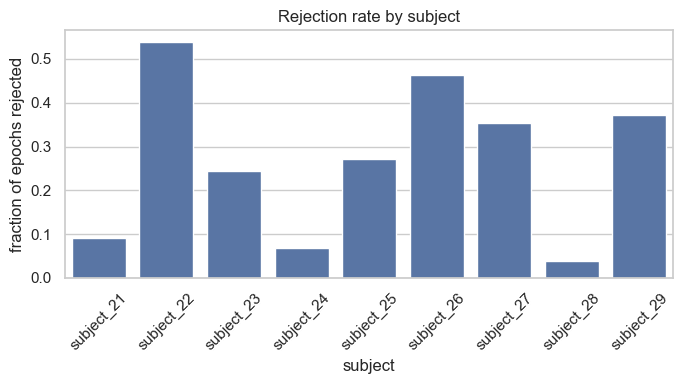

In [132]:
def autoreject_report(epochs_dict, n_interpolate=(1, 4, 8), random_state=42):
    from autoreject import AutoReject

    out = []
    cleaned = defaultdict(dict)
    for sub, ses, ep in iter_sessions(epochs_dict):
        ep = get_pinchlog(ep).copy().pick("eeg").load_data()
        ar = AutoReject(n_interpolate=np.array(n_interpolate),
                        random_state=random_state, n_jobs=-1, verbose=False)
        ep_clean, log = ar.fit_transform(ep, return_log=True)
        cleaned[sub][ses] = ep_clean
        md = ep.metadata.reset_index(drop=True)
        for cls in CLASSES:
            m = (md[META_COL] == cls).values
            if m.sum() == 0:
                continue
            out.append(dict(subject=sub, session=ses, **{META_COL: cls},
                            n=int(m.sum()),
                            dropped=int(log.bad_epochs[m].sum()),
                            drop_rate=float(log.bad_epochs[m].mean())))
    df = pd.DataFrame(out)

    # Aggregate across sessions/classes to get one drop rate per subject
    sub_df = (df.groupby("subject", as_index=False)[["n", "dropped"]].sum())
    sub_df["drop_rate"] = sub_df["dropped"] / sub_df["n"]
    sub_order = sorted(sub_df["subject"].unique())

    fig, ax = plt.subplots(figsize=(7, 4))
    sns.barplot(data=sub_df, x="subject", y="drop_rate", order=sub_order,
                errorbar=None, ax=ax)
    ax.set(ylabel="fraction of epochs rejected",
           title="Rejection rate by subject")
    ax.tick_params(axis="x", rotation=45)
    fig.tight_layout()
    return fig, df, dict(cleaned)

_, drop_df, clean = autoreject_report(epochs)

# Conclusion

Overall measurement quality was suboptimal. The measurements of some subjects are best left out to not poison the remaining measurements, most notably subject 22 and 26.

This conclusion was derrived based on the number of bad electrodes, number of rejected epochs, and PSD characteristics.